In [1]:
import torch
import torchvision.transforms as transforms

from torchvision import models
from PIL import Image

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

In [2]:
resnet = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

resnet.eval()

print("ResNet50 Loaded")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\soora/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100.0%


ResNet50 Loaded


In [3]:
feature_extractor = torch.nn.Sequential(
    *list(resnet.children())[:-1]
)

feature_extractor.eval()

print("Feature Extractor Ready")

Feature Extractor Ready


In [4]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

In [5]:
image_path = Path(
    "../dataset/Apple/Train/Apple Scab"
)

sample_image = list(
    image_path.glob("*")
)[0]

print(sample_image)

..\dataset\Apple\Train\Apple Scab\00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG


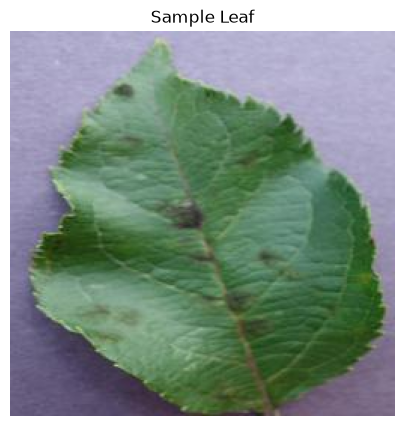

In [6]:
img = Image.open(
    sample_image
).convert("RGB")

plt.figure(figsize=(5,5))

plt.imshow(img)

plt.title("Sample Leaf")

plt.axis("off")

plt.show()

In [7]:
img_tensor = transform(img)

print(img_tensor.shape)

torch.Size([3, 224, 224])


In [8]:
img_tensor = img_tensor.unsqueeze(0)

print(img_tensor.shape)

torch.Size([1, 3, 224, 224])


In [9]:
with torch.no_grad():

    embedding = feature_extractor(
        img_tensor
    )

In [10]:
print(embedding.shape)

torch.Size([1, 2048, 1, 1])


In [11]:
embedding = embedding.squeeze()

print(embedding.shape)

torch.Size([2048])


In [12]:
embedding_np = embedding.numpy()

print(type(embedding_np))

print(embedding_np.shape)

<class 'numpy.ndarray'>
(2048,)


In [13]:
print(
    embedding_np[:20]
)

[0.00581609 1.1160598  0.         0.         0.         0.
 0.52013475 0.         0.         0.         0.0711711  0.
 0.02581922 0.01350416 0.00393672 0.         0.06187056 0.01594845
 0.         0.00991239]


In [14]:
def get_embedding(image_path):

    img = Image.open(image_path).convert("RGB")

    img_tensor = transform(img)

    img_tensor = img_tensor.unsqueeze(0)

    with torch.no_grad():
        embedding = feature_extractor(img_tensor)

    embedding = embedding.squeeze()

    return embedding.numpy()

In [15]:
import numpy as np
from numpy.linalg import norm

In [16]:
def cosine_similarity(a, b):

    return np.dot(a, b) / (
        norm(a) * norm(b)
    )

In [25]:
from pathlib import Path

apple_scab_folder = Path(
    "../dataset/Apple/Train/Apple Scab"
)

apple_healthy = Path(
    "../dataset/Apple/Train/Healthy"
)

images1 = list(
    apple_scab_folder.glob("*")
)

images2 = list(
    apple_healthy.glob("*")
)

print("Apple Scab Images:", len(images1))
print("Apple Healthy Images:", len(images2))

Apple Scab Images: 2016
Apple Healthy Images: 2008


In [57]:
#Same Diseases Average

import random
import numpy as np

same_scores = []

for _ in range(20):

    path1 = random.choice(images1)
    path2 = random.choice(images1)

    emb1 = get_embedding(path1)
    emb2 = get_embedding(path2)

    score = cosine_similarity(
        emb1,
        emb2
    )

    same_scores.append(score)

print("Same Disease Results")
print("--------------------")
print("Average:", np.mean(same_scores))
print("Std Dev:", np.std(same_scores))
print("Minimum:", np.min(same_scores))
print("Maximum:", np.max(same_scores))

Same Disease Results
--------------------
Average: 0.6796995
Std Dev: 0.09690137
Minimum: 0.45198938
Maximum: 0.81378627


In [58]:
#Different Diseases Average

diff_scores = []

for _ in range(20):

    path1 = random.choice(images1)   # Apple Scab
    path2 = random.choice(images2)   # Healthy

    emb1 = get_embedding(path1)
    emb2 = get_embedding(path2)

    score = cosine_similarity(
        emb1,
        emb2
    )

    diff_scores.append(score)

print("Different Disease Results")
print("-------------------------")
print("Average:", np.mean(diff_scores))
print("Std Dev:", np.std(diff_scores))
print("Minimum:", np.min(diff_scores))
print("Maximum:", np.max(diff_scores))

Different Disease Results
-------------------------
Average: 0.6069039
Std Dev: 0.07564449
Minimum: 0.4471058
Maximum: 0.72952974


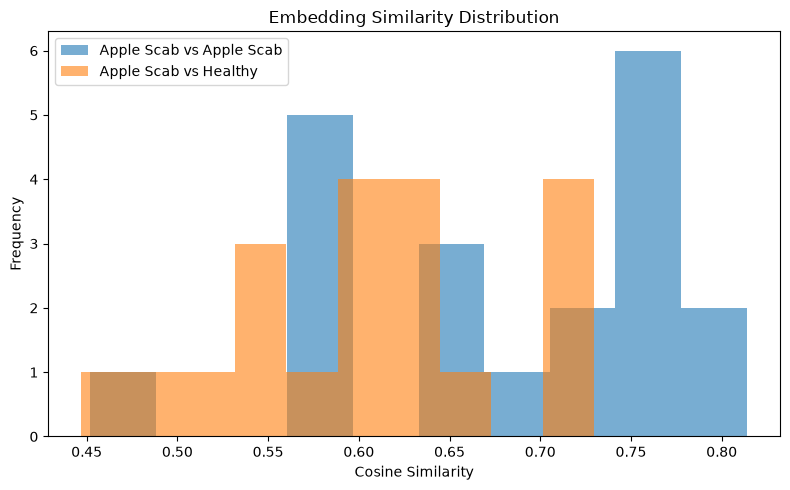

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    same_scores,
    bins=10,
    alpha=0.6,
    label="Apple Scab vs Apple Scab"
)

plt.hist(
    diff_scores,
    bins=10,
    alpha=0.6,
    label="Apple Scab vs Healthy"
)

plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")
plt.title("Embedding Similarity Distribution")

plt.legend()

plt.tight_layout()

plt.savefig(
    "../results/similarity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [61]:
print("Same Disease Average:", np.mean(same_scores))
print("Same Disease Std:", np.std(same_scores))

print()

print("Different Disease Average:", np.mean(diff_scores))
print("Different Disease Std:", np.std(diff_scores))

Same Disease Average: 0.6796995
Same Disease Std: 0.09690137

Different Disease Average: 0.6069039
Different Disease Std: 0.07564449
